# Customer Segmentation without Produce & Dairy Eggs

This notebook performs customer segmentation using behavioral features plus department preference features, but excludes the very common departments `produce` and `dairy eggs` to make niche preferences more visible.

Main idea:
- Keep behavioral features: `total_orders`, `avg_days_between_orders`, `reorder_ratio`
- Use department preference ratios
- Remove common departments: `produce`, `dairy eggs`
- Apply StandardScaler + K-means
- Visualize results with elbow plot, heatmap, PCA, and cluster profile charts


In [19]:
import pandas as pd

DATA_PATH = "../data/raw/"
PROCESSED_PATH = "../data/processed/"

orders = pd.read_csv(DATA_PATH + "orders.csv")
order_products_prior = pd.read_csv(DATA_PATH + "order_products__prior.csv")
products = pd.read_csv(DATA_PATH + "products.csv")
departments = pd.read_csv(DATA_PATH + "departments.csv")

user_features = pd.read_csv(
    PROCESSED_PATH + "user_features.csv",
    index_col=0
)


In [ ]:
user_orders = orders[[
    "order_id",
    "user_id"
]]

order_detail = order_products_prior.merge(
    user_orders,
    on="order_id",
    how="left"
)

order_detail = order_detail.merge(
    products,
    on="product_id",
    how="left"
)

order_detail = order_detail.merge(
    departments,
    on="department_id",
    how="left"
)

order_detail.head()

order_detail.csv saved!


,order_id,product_id,add_to_cart_order,reordered,user_id,product_name,aisle_id,department_id,department
0,2,33120,1,1,202279,Organic Egg Whites,86,16,dairy eggs
1,2,28985,2,1,202279,Michigan Organic Kale,83,4,produce
2,2,9327,3,0,202279,Garlic Powder,104,13,pantry
3,2,45918,4,1,202279,Coconut Butter,19,13,pantry
4,2,30035,5,0,202279,Natural Sweetener,17,13,pantry


In [21]:
department_counts = pd.crosstab(
    order_detail["user_id"],
    order_detail["department"]
)

department_counts.head()

department,alcohol,babies,bakery,beverages,breakfast,bulk,canned goods,dairy eggs,deli,dry goods pasta,...,household,international,meat seafood,missing,other,pantry,personal care,pets,produce,snacks
user_id,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,13,3,0,0,13,0,0,...,2,0,0,0,0,1,0,0,5,22
2,0,0,2,9,3,0,1,48,21,0,...,0,3,1,0,0,11,1,0,36,42
3,0,0,0,3,0,0,0,21,2,4,...,1,0,0,0,0,4,0,0,38,9
4,2,0,2,3,0,0,1,0,2,0,...,2,0,0,0,0,0,0,0,2,1
5,0,0,0,0,0,0,1,8,1,1,...,0,2,0,0,0,2,0,0,19,1


In [22]:
department_ratio = department_counts.div(
    department_counts.sum(axis=1),
    axis=0
)

department_ratio.head()

department,alcohol,babies,bakery,beverages,breakfast,bulk,canned goods,dairy eggs,deli,dry goods pasta,...,household,international,meat seafood,missing,other,pantry,personal care,pets,produce,snacks
user_id,,,,,,,,,,,,,,,,,,,,,
1,0.000000,0.0,0.000000,0.220339,0.050847,0.0,0.000000,0.220339,0.000000,0.000000,...,0.033898,0.000000,0.000000,0.0,0.0,0.016949,0.000000,0.0,0.084746,0.372881
2,0.000000,0.0,0.010256,0.046154,0.015385,0.0,0.005128,0.246154,0.107692,0.000000,...,0.000000,0.015385,0.005128,0.0,0.0,0.056410,0.005128,0.0,0.184615,0.215385
3,0.000000,0.0,0.000000,0.034091,0.000000,0.0,0.000000,0.238636,0.022727,0.045455,...,0.011364,0.000000,0.000000,0.0,0.0,0.045455,0.000000,0.0,0.431818,0.102273
4,0.111111,0.0,0.111111,0.166667,0.000000,0.0,0.055556,0.000000,0.111111,0.000000,...,0.111111,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.111111,0.055556
5,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.027027,0.216216,0.027027,0.027027,...,0.000000,0.054054,0.000000,0.0,0.0,0.054054,0.000000,0.0,0.513514,0.027027


## Remove Common Departments

`produce` and `dairy eggs` are purchased by many customers, so they may dominate the clustering and hide more specific preferences such as pets, alcohol, frozen food, deli, and household products.

In [23]:
common_departments = ["produce", "dairy eggs"]

department_ratio_filtered = department_ratio.drop(
    columns=common_departments,
    errors="ignore"
)

department_ratio_filtered.head()

department,alcohol,babies,bakery,beverages,breakfast,bulk,canned goods,deli,dry goods pasta,frozen,household,international,meat seafood,missing,other,pantry,personal care,pets,snacks
user_id,,,,,,,,,,,,,,,,,,,
1,0.000000,0.0,0.000000,0.220339,0.050847,0.0,0.000000,0.000000,0.000000,0.000000,0.033898,0.000000,0.000000,0.0,0.0,0.016949,0.000000,0.0,0.372881
2,0.000000,0.0,0.010256,0.046154,0.015385,0.0,0.005128,0.107692,0.000000,0.087179,0.000000,0.015385,0.005128,0.0,0.0,0.056410,0.005128,0.0,0.215385
3,0.000000,0.0,0.000000,0.034091,0.000000,0.0,0.000000,0.022727,0.045455,0.068182,0.011364,0.000000,0.000000,0.0,0.0,0.045455,0.000000,0.0,0.102273
4,0.111111,0.0,0.111111,0.166667,0.000000,0.0,0.055556,0.111111,0.000000,0.166667,0.111111,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.055556
5,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.027027,0.027027,0.027027,0.054054,0.000000,0.054054,0.000000,0.0,0.0,0.054054,0.000000,0.0,0.027027


In [24]:
enhanced_features = user_features.merge(
    department_ratio_filtered,
    left_index=True,
    right_index=True,
    how="left"
)

enhanced_features.head()

,total_orders,avg_days_between_orders,reorder_ratio,alcohol,babies,bakery,beverages,breakfast,bulk,canned goods,...,frozen,household,international,meat seafood,missing,other,pantry,personal care,pets,snacks
user_id,,,,,,,,,,,,,,,,,,,,,
1,11,19.000000,0.694915,0.000000,0.0,0.000000,0.220339,0.050847,0.0,0.000000,...,0.000000,0.033898,0.000000,0.000000,0.0,0.0,0.016949,0.000000,0.0,0.372881
2,15,16.285714,0.476923,0.000000,0.0,0.010256,0.046154,0.015385,0.0,0.005128,...,0.087179,0.000000,0.015385,0.005128,0.0,0.0,0.056410,0.005128,0.0,0.215385
3,13,12.000000,0.625000,0.000000,0.0,0.000000,0.034091,0.000000,0.0,0.000000,...,0.068182,0.011364,0.000000,0.000000,0.0,0.0,0.045455,0.000000,0.0,0.102273
4,6,17.000000,0.055556,0.111111,0.0,0.111111,0.166667,0.000000,0.0,0.055556,...,0.166667,0.111111,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.055556
5,5,11.500000,0.378378,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.027027,...,0.054054,0.000000,0.054054,0.000000,0.0,0.0,0.054054,0.000000,0.0,0.027027


In [25]:
from sklearn.preprocessing import StandardScaler

# Fill possible missing values after merge
features_for_clustering = enhanced_features.fillna(0)

scaler = StandardScaler()

scaled_features = scaler.fit_transform(features_for_clustering)

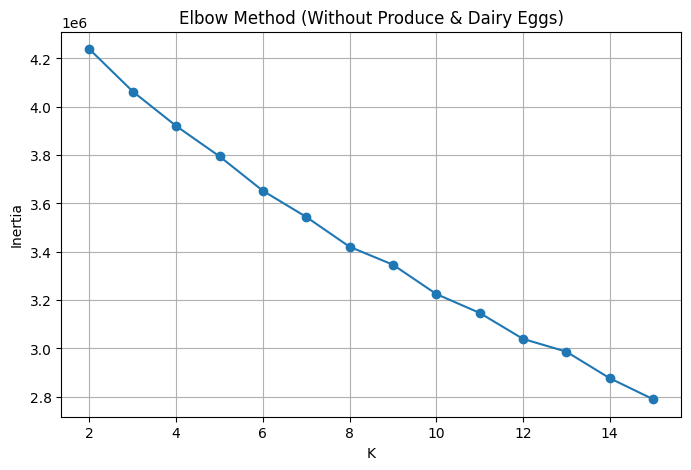

In [26]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

K_range = range(2, 16)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_features)

    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))

plt.plot(K_range, inertia, marker='o')

plt.title("Elbow Method (Without Produce & Dairy Eggs)")
plt.xlabel("K")
plt.ylabel("Inertia")

plt.grid(True)

plt.show()

In [127]:
kmeans = KMeans(
    n_clusters=9,
    random_state=42
)

clusters = kmeans.fit_predict(
    scaled_features
)

enhanced_features["cluster"] = clusters

In [128]:
cluster_summary = enhanced_features.groupby(
    "cluster"
).mean()

cluster_summary

,total_orders,avg_days_between_orders,reorder_ratio,alcohol,babies,bakery,beverages,breakfast,bulk,canned goods,...,frozen,household,international,meat seafood,missing,other,pantry,personal care,pets,snacks
cluster,,,,,,,,,,,,,,,,,,,,,
0,13.341014,16.398684,0.497223,0.005421,0.001001,0.012291,0.326110,0.034495,0.002117,0.006152,...,0.026846,0.029596,0.002522,0.004014,0.001281,0.001023,0.031698,0.012131,0.000889,0.251855
1,10.604647,17.204736,0.385879,0.005231,0.003499,0.129640,0.079572,0.030997,0.000484,0.022099,...,0.062770,0.023520,0.004924,0.022949,0.000964,0.000973,0.058051,0.012996,0.002043,0.084087
2,10.249673,16.314896,0.375924,0.003447,0.003246,0.026495,0.086128,0.022776,0.000464,0.023915,...,0.250166,0.021751,0.005977,0.016050,0.012120,0.001276,0.049671,0.016195,0.003172,0.087511
3,10.708382,18.436444,0.311165,0.007723,0.007127,0.019381,0.126784,0.020455,0.000119,0.017656,...,0.045358,0.225143,0.004449,0.009828,0.002569,0.007302,0.057729,0.128794,0.040330,0.069433
4,9.004332,18.400446,0.279476,0.004847,0.003227,0.029013,0.064895,0.018650,0.000709,0.075951,...,0.062032,0.024900,0.020802,0.027481,0.001457,0.001189,0.105993,0.013651,0.002116,0.061821
5,10.728818,16.764596,0.404529,0.003664,0.004378,0.022954,0.073051,0.018338,0.001042,0.023596,...,0.055304,0.018158,0.004671,0.028477,0.001308,0.000967,0.051464,0.011378,0.001467,0.073488
6,13.005013,15.471045,0.366304,0.472934,0.001306,0.017189,0.108701,0.008803,0.000101,0.010771,...,0.037210,0.034392,0.003704,0.008855,0.000986,0.006052,0.034816,0.010334,0.002784,0.067645
7,43.552590,7.878781,0.686543,0.003257,0.008227,0.033421,0.078584,0.020642,0.001297,0.029017,...,0.060172,0.018867,0.007298,0.020693,0.001778,0.001011,0.055092,0.012019,0.001873,0.082122
8,16.845388,14.539127,0.420814,0.002257,0.208850,0.028790,0.060478,0.019857,0.000462,0.025364,...,0.061978,0.030252,0.005328,0.016368,0.002890,0.002397,0.041654,0.018898,0.001891,0.065119


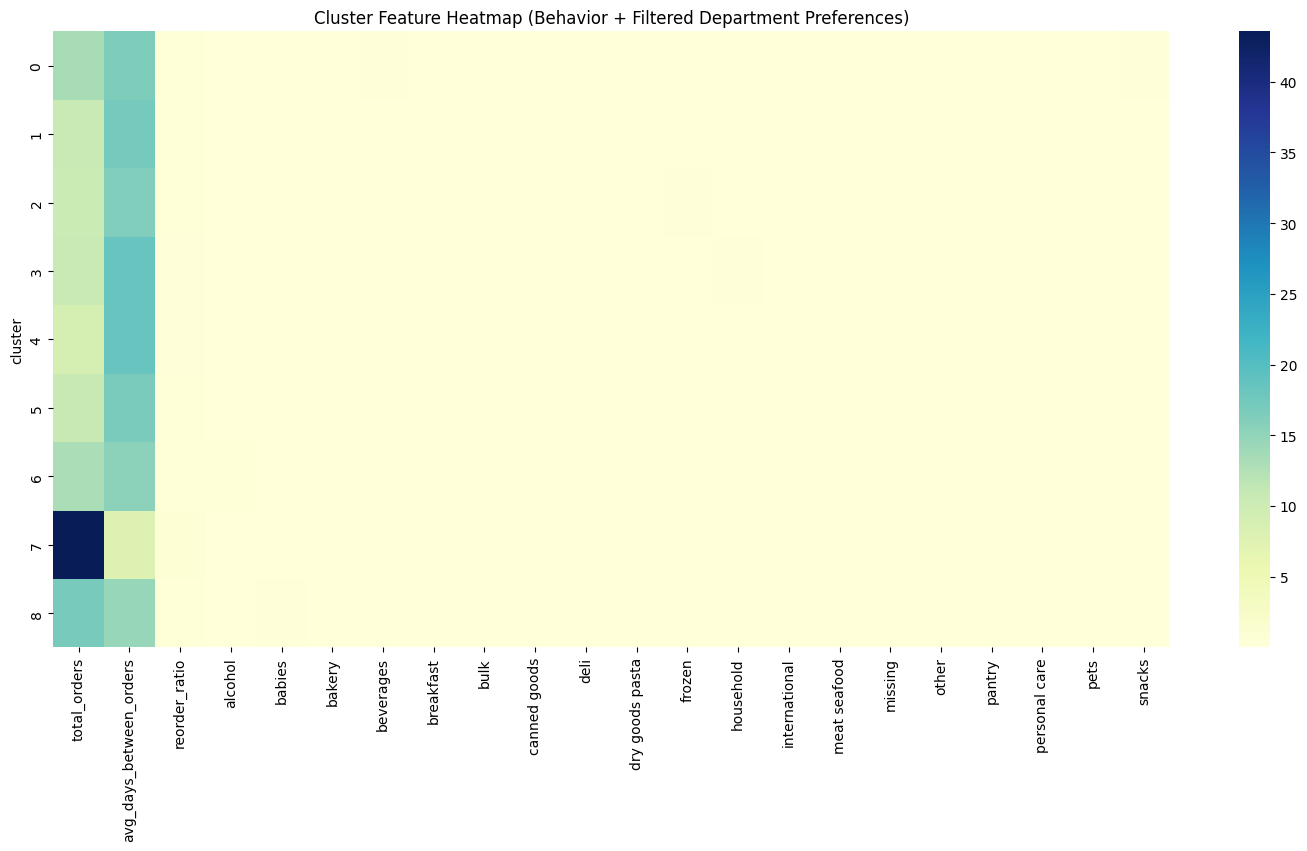

In [129]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 8))

sns.heatmap(
    cluster_summary,
    cmap="YlGnBu",
    annot=False
)

plt.title("Cluster Feature Heatmap (Behavior + Filtered Department Preferences)")

plt.show()

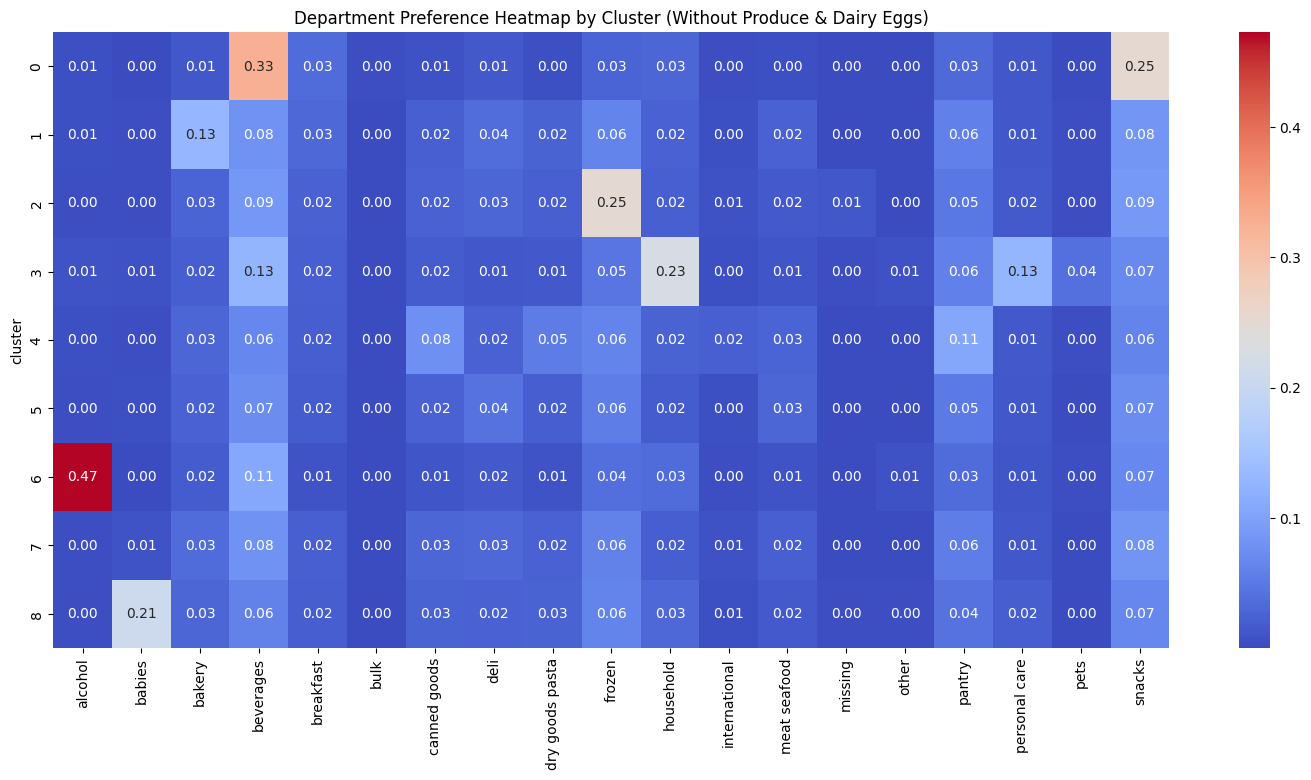

In [130]:
import seaborn as sns
import matplotlib.pyplot as plt

# Only department preference features, excluding produce and dairy eggs
department_columns = [
    col for col in department_ratio_filtered.columns
    if col in cluster_summary.columns
]

plt.figure(figsize=(18, 8))

sns.heatmap(
    cluster_summary[department_columns],
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Department Preference Heatmap by Cluster (Without Produce & Dairy Eggs)")

plt.show()

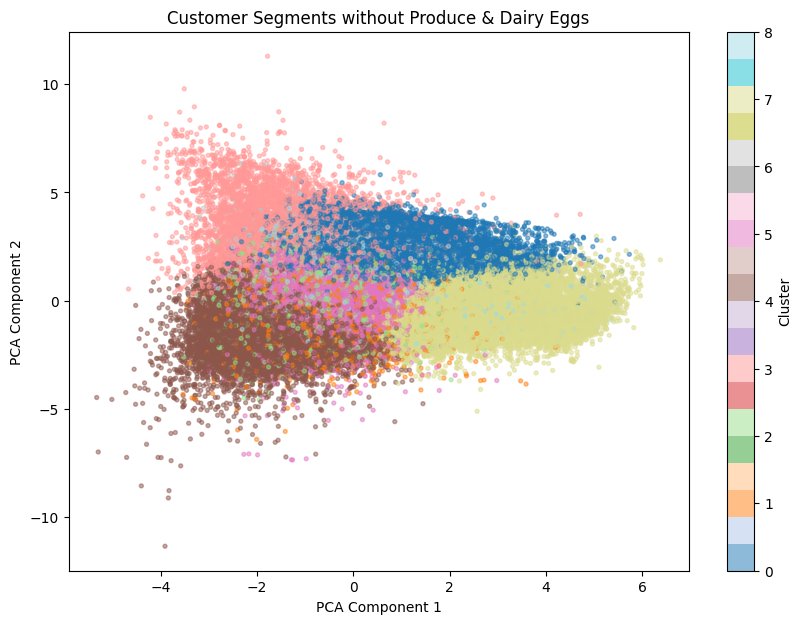

In [131]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_result = pca.fit_transform(scaled_features)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    pca_result[:, 0],
    pca_result[:, 1],
    c=enhanced_features["cluster"],
    cmap="tab20",
    alpha=0.5,
    s=8
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")

plt.title("Customer Segments without Produce & Dairy Eggs")

plt.colorbar(scatter, label="Cluster")

plt.show()

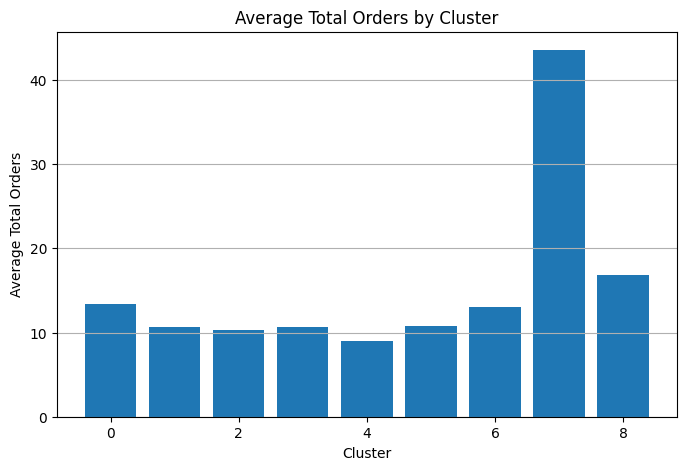

In [132]:
import matplotlib.pyplot as plt

cluster_summary = enhanced_features.groupby("cluster").mean()

plt.figure(figsize=(8,5))

plt.bar(
    cluster_summary.index,
    cluster_summary["total_orders"]
)

plt.title("Average Total Orders by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Total Orders")

plt.grid(axis="y")

plt.show()

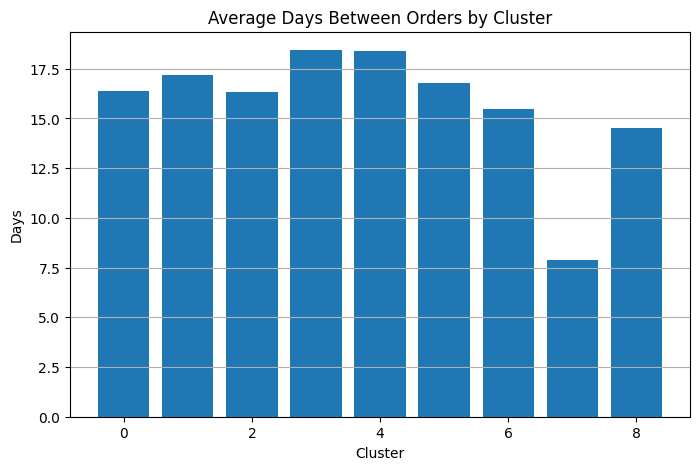

In [133]:
plt.figure(figsize=(8,5))

plt.bar(
    cluster_summary.index,
    cluster_summary["avg_days_between_orders"]
)

plt.title("Average Days Between Orders by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Days")

plt.grid(axis="y")

plt.show()

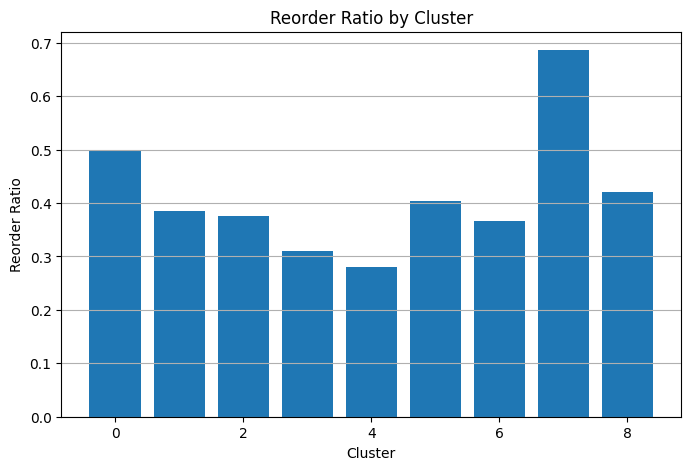

In [134]:
plt.figure(figsize=(8,5))

plt.bar(
    cluster_summary.index,
    cluster_summary["reorder_ratio"]
)

plt.title("Reorder Ratio by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Reorder Ratio")

plt.grid(axis="y")

plt.show()

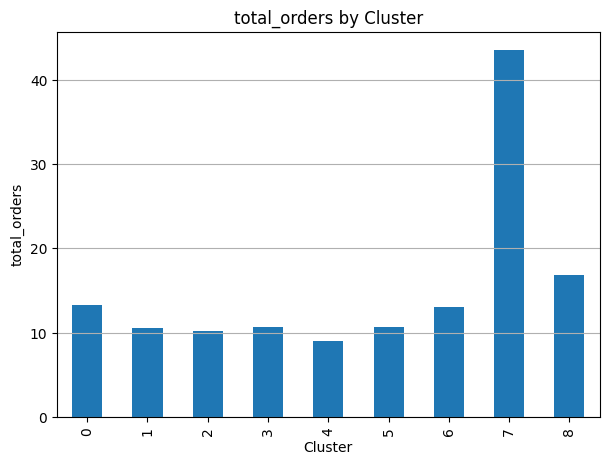

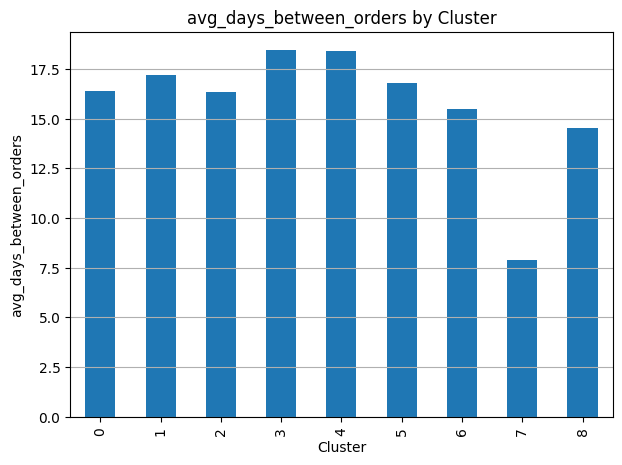

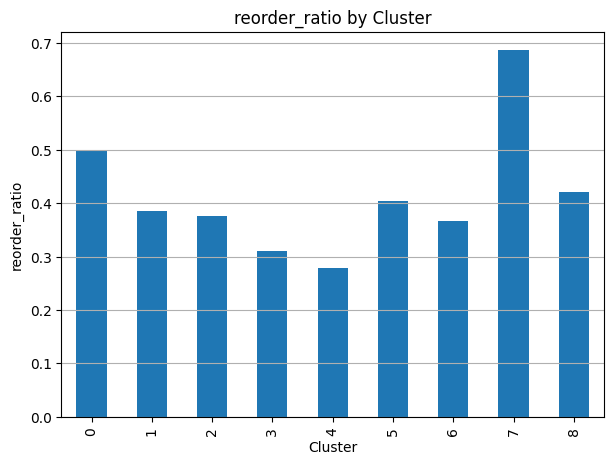

In [135]:
# Behavioral feature columns
behavior_cols = [
    "total_orders",
    "avg_days_between_orders",
    "reorder_ratio"
]

# 如果之後有 avg_basket_size，才自動加入
if "avg_basket_size" in cluster_summary.columns:
    behavior_cols.append("avg_basket_size")

for col in behavior_cols:
    plt.figure(figsize=(7, 5))

    cluster_summary[col].plot(kind="bar")

    plt.title(f"{col} by Cluster")
    plt.xlabel("Cluster")
    plt.ylabel(col)

    plt.grid(axis="y")
    plt.show()

## Top Department Preference per Cluster

This section shows the top departments for each cluster after removing `produce` and `dairy eggs`. These charts are useful for interpreting fine-grained recommendation groups.

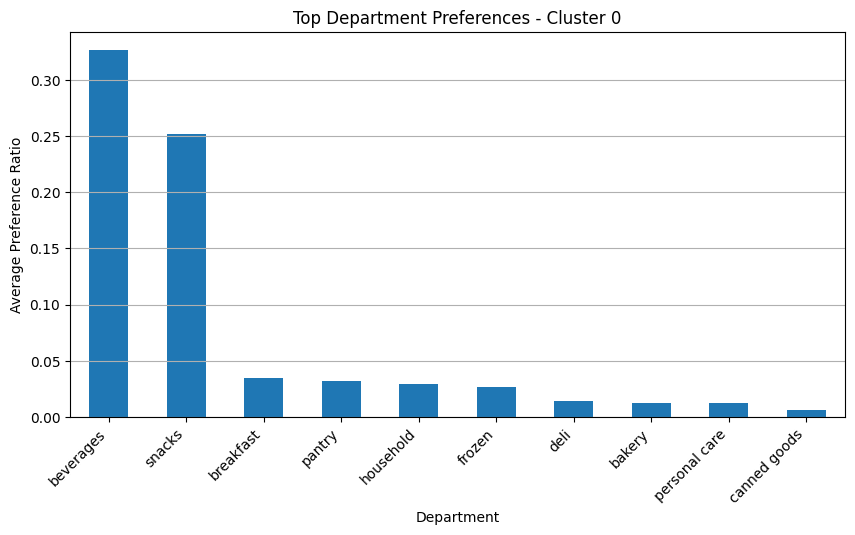

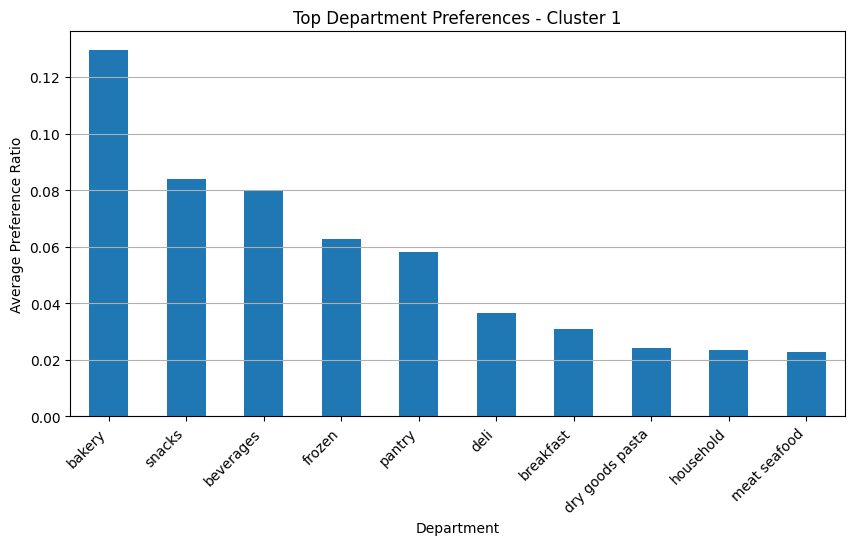

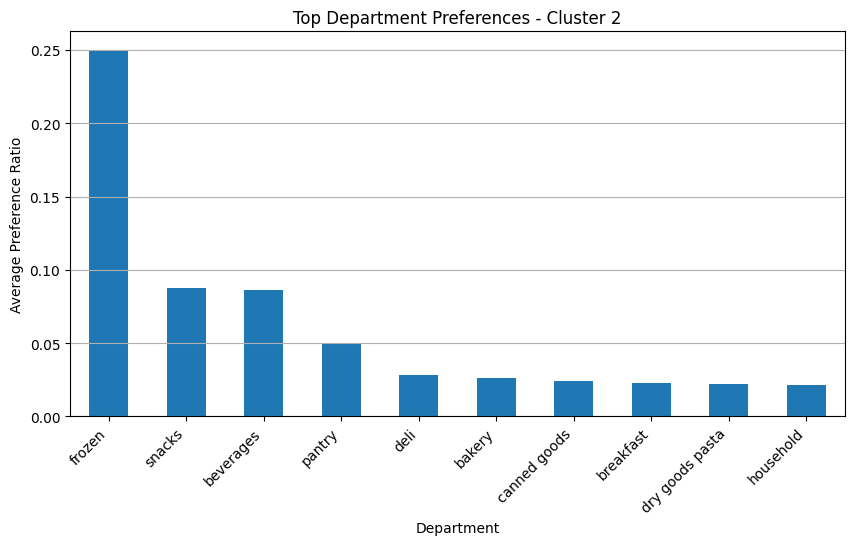

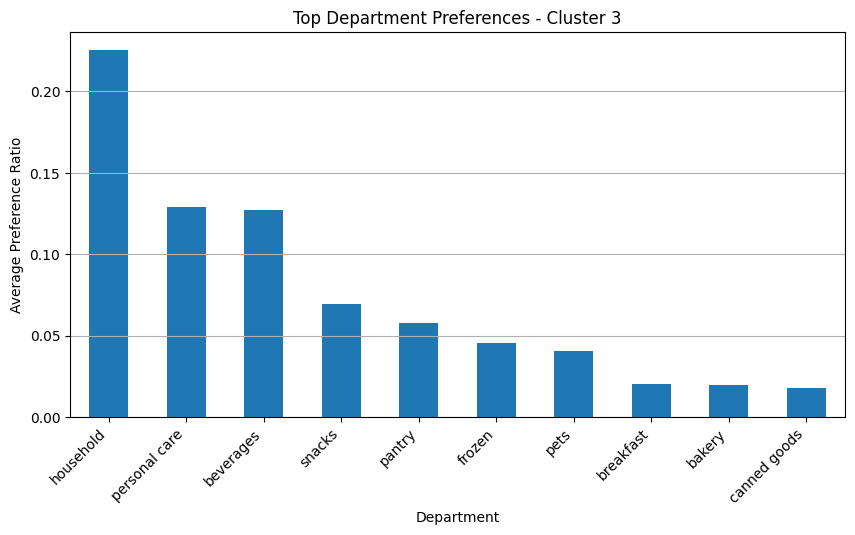

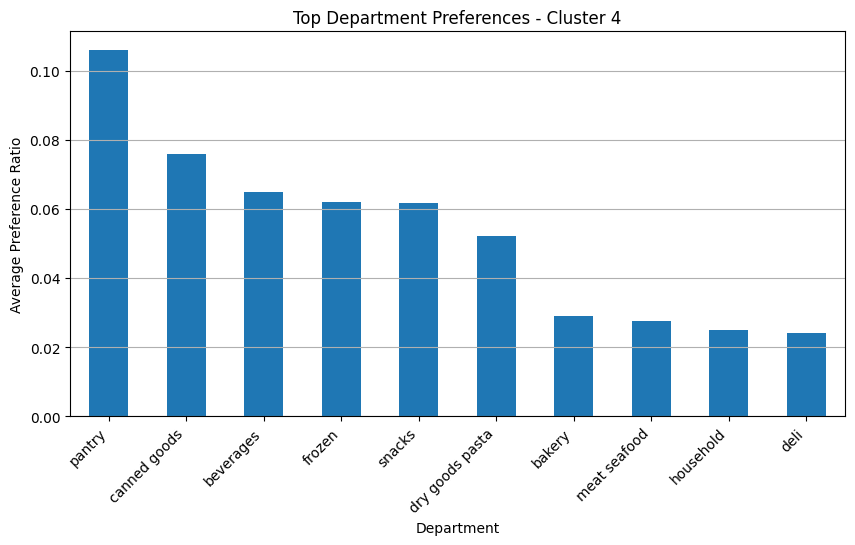

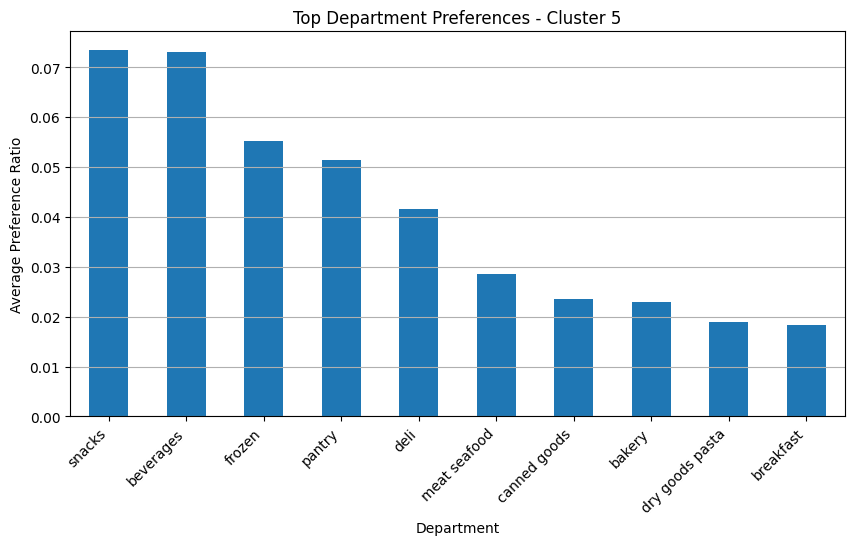

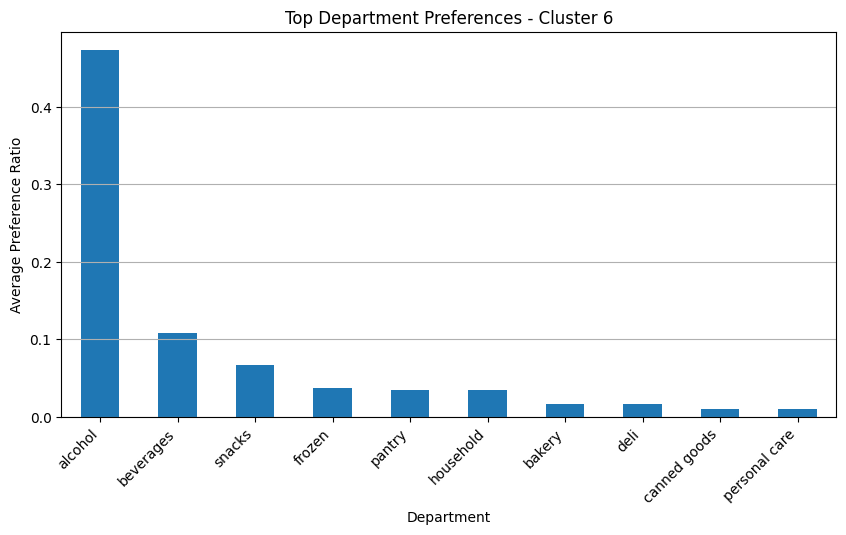

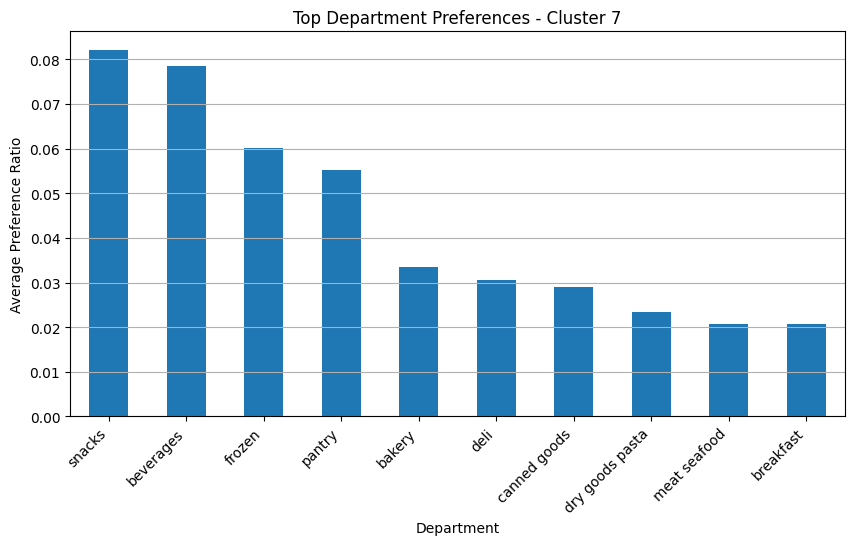

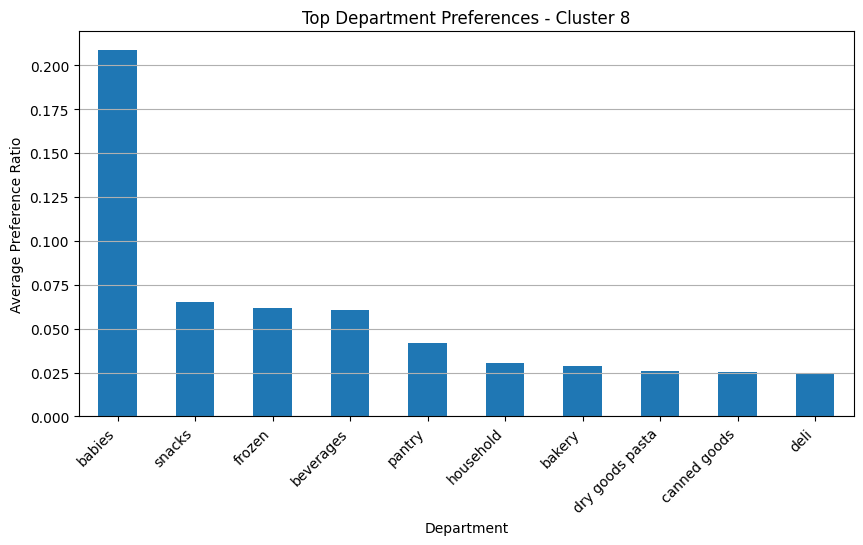

In [136]:
for cluster_id in sorted(enhanced_features["cluster"].unique()):
    top_departments = (
        cluster_summary.loc[cluster_id, department_columns]
        .sort_values(ascending=False)
        .head(10)
    )

    plt.figure(figsize=(10, 5))
    top_departments.plot(kind="bar")

    plt.title(f"Top Department Preferences - Cluster {cluster_id}")
    plt.xlabel("Department")
    plt.ylabel("Average Preference Ratio")
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y")
    plt.show()

## Save Segmentation Results

In [137]:
enhanced_features.to_csv(
    PROCESSED_PATH + "customer_segments_without_produce_dairy.csv"
)

print("Saved to:", PROCESSED_PATH + "customer_segments_without_produce_dairy.csv")

Saved to: ../data/processed/customer_segments_without_produce_dairy.csv


In [138]:
cluster_counts = (
    enhanced_features["cluster"]
    .value_counts()
    .sort_index()
)

print(cluster_counts)

cluster
0    16753
1    18118
2    16842
3     7647
4    37399
5    66140
6     1995
7    36794
8     4521
Name: count, dtype: int64


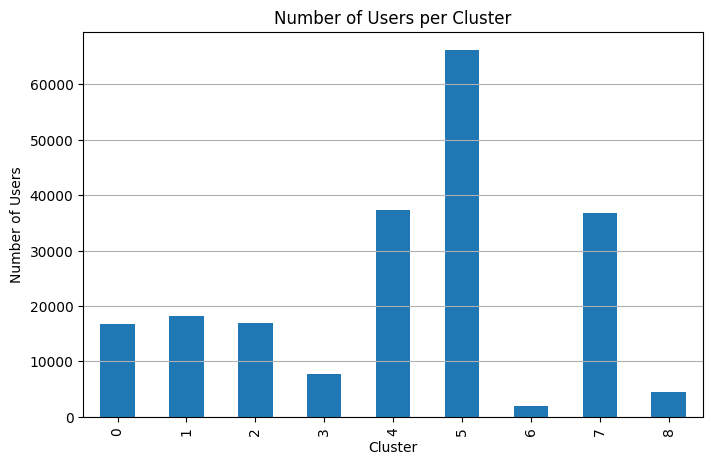

In [139]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

cluster_counts.plot(kind="bar")

plt.title("Number of Users per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Users")

plt.grid(axis="y")

plt.show()